# Pergunta de Pesquisa 5 (PP5)

In [5]:
import json
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np
import pandas as pd
from IPython.display import display

# Estilo visual padronizado para o TCC
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 10
plt.rcParams['axes.titlesize'] = 11.5
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['axes.labelsize'] = 10.5
plt.rcParams['axes.labelweight'] = 'bold'
plt.rcParams['xtick.labelsize'] = 9.5
plt.rcParams['ytick.labelsize'] = 9.5
plt.rcParams['legend.fontsize'] = 9.2
plt.rcParams['figure.titlesize'] = 13
plt.rcParams['figure.dpi'] = 120

PALETTE_GEN = {'Anterior': '#6c757d', 'Atual': '#2a9d8f'}
PALETTE_FAMILY = {'Gemini': '#1a73e8', 'GPT': '#10a37f'}
PALETTE_VERDICTS = {
    'AC': '#2ca02c', 'WA': '#d62728', 'RE': '#9467bd',
    'TLE': '#ff7f0e', 'MLE': '#8c564b', 'CE': '#7f7f7f'
}

CSV_PATH = Path("../results/dataset_obi_senior/llms_compare.csv")
DB_PATH = Path("../database/dataset_obi_senior")
TCC_RES_PATH = Path("../results/dataset_obi_senior")

df = pd.read_csv(CSV_PATH, keep_default_na=True)
N = len(df)

# Enriquece com metadados oficiais (ano e etapa da OBI) do próprio repositório
meta_rows = []
for q in df["question_name"]:
    pj = DB_PATH / q / "problem.json"
    d = json.loads(pj.read_text(encoding="utf-8"))
    per = str(d.get("period", "-"))
    if per in ("Fase 1", "Fase Local"):
        fase = "Fase 1 / Local"
    elif per in ("Fase 2", "Fase 2 - Turno B", "Fase Estadual"):
        fase = "Fase 2 / Estadual"
    else:
        fase = "Fase 3 / Nacional"
    meta_rows.append({"question_name": q, "year": str(d.get("year", "-")), "fase": fase})

df = df.merge(pd.DataFrame(meta_rows), on="question_name", how="left")

# Pares intrafamília completos em Python Zero-Shot (Gemini e GPT)
MODELS = [
    ("Gemini 3.1 Pro",   "Gemini", "Anterior", "Flagship", "gemini_3_1_pro"),
    ("Gemini 3.8 Flash", "Gemini", "Atual",    "Compacto", "gemini_3_8_flash"),
    ("GPT-5.4",          "GPT",    "Anterior", "Flagship", "gpt_5_4"),
    ("GPT-6 Luna",       "GPT",    "Atual",    "Compacto", "gpt_6_luna"),
]

# Tabela 1: Consolidado Geral (n = 46)
summary_rows = []
for name, fam, gen, tier, slug in MODELS:
    vcol, tcol, ccol = f"veredito_{slug}", f"tokens_{slug}", f"custo_{slug}"
    vc = df[vcol].value_counts()
    ac = int(vc.get("AC", 0))
    cost = float(df[ccol].sum())
    summary_rows.append({
        "Modelo": name, "Família": fam, "Geração": gen, "Porte": tier,
        "AC": ac, "Pass@1 (%)": round(ac / N * 100, 2),
        "WA": int(vc.get("WA", 0)), "RE": int(vc.get("RE", 0)),
        "TLE": int(vc.get("TLE", 0)), "CE": int(vc.get("CE", 0)),
        "Tokens Médios": round(float(df[tcol].mean()), 1),
        "Custo Total (USD)": round(cost, 4),
        "Custo / AC (USD)": round(cost / ac, 5) if ac > 0 else np.nan,
    })

df_summary = pd.DataFrame(summary_rows)

print(f"Base carregada: {CSV_PATH.name} ({N} questões do OBI Sênior, 2016–2025 | 100% Python Zero-Shot, T = 0.0)")
print("Distribuição por etapa:", df["fase"].value_counts().to_dict())

print("\n=== TABELA 1: DESEMPENHO CONSOLIDADO SOB PARIDADE DE JUÍZ (n = 46) ===")
display(df_summary)

# Tabela 2: Comparação Intrafamília Direta (Gemini e GPT)
pair_rows = []
for fam, m_old, m_new in [("Gemini", "Gemini 3.1 Pro", "Gemini 3.8 Flash"), ("GPT", "GPT-5.4", "GPT-6 Luna")]:
    ro = df_summary[df_summary["Modelo"] == m_old].iloc[0]
    rn = df_summary[df_summary["Modelo"] == m_new].iloc[0]
    pair_rows.append({
        "Família": fam,
        "Anterior → Atual": f"{m_old} → {m_new}",
        "AC (46)": f"{int(ro['AC'])} → {int(rn['AC'])} ({int(rn['AC'] - ro['AC']):+d})",
        "Δ Pass@1 (p.p.)": round(rn["Pass@1 (%)"] - ro["Pass@1 (%)"], 2),
        "Δ Tokens (%)": round((rn["Tokens Médios"] / ro["Tokens Médios"] - 1) * 100, 1),
        "Custo / AC (Ant. → Atual)": f"${ro['Custo / AC (USD)']:.5f} → ${rn['Custo / AC (USD)']:.5f}",
        "Redução Custo/AC": f"{ro['Custo / AC (USD)'] / rn['Custo / AC (USD)']:.1f}× mais barato",
    })
print("\n=== TABELA 2: EVOLUÇÃO INTRAFAMÍLIA DIRETA (FLAGSHIP ANTERIOR → COMPACTO ATUAL) ===")
display(pd.DataFrame(pair_rows))

# Nota de auditoria: impacto do artefato de gabarito em 'Construção de Rodovia' (WA unânime nos 4 modelos)
df_adj = df[df["question_name"] != "Construção de Rodovia"]
print("\n=== NOTA DE SENSIBILIDADE: EXCLUINDO 'Construção de Rodovia' (n = 45, artefato de gabarito direcionado/múltiplas saídas) ===")
for name, _, _, _, slug in MODELS:
    vcol = f"veredito_{slug}"
    ac45 = int((df_adj[vcol] == "AC").sum())
    print(f"  {name:18s}: {ac45:2d}/45 ({ac45/45*100:6.2f}%)")

Base carregada: llms_compare.csv (46 questões do OBI Sênior, 2016–2025 | 100% Python Zero-Shot, T = 0.0)
Distribuição por etapa: {'Fase 1 / Local': 16, 'Fase 3 / Nacional': 16, 'Fase 2 / Estadual': 14}

=== TABELA 1: DESEMPENHO CONSOLIDADO SOB PARIDADE DE JUÍZ (n = 46) ===


,Modelo,Família,Geração,Porte,AC,Pass@1 (%),WA,RE,TLE,CE,Tokens Médios,Custo Total (USD),Custo / AC (USD)
0,Gemini 3.1 Pro,Gemini,Anterior,Flagship,45,97.83,1,0,0,0,6025.5,2.8602,0.06356
1,Gemini 3.8 Flash,Gemini,Atual,Compacto,44,95.65,2,0,0,0,2940.4,0.0994,0.00226
2,GPT-5.4,GPT,Anterior,Flagship,31,67.39,12,2,1,0,1206.4,0.3013,0.00972
3,GPT-6 Luna,GPT,Atual,Compacto,38,82.61,6,0,2,0,2044.9,0.0316,0.00083



=== TABELA 2: EVOLUÇÃO INTRAFAMÍLIA DIRETA (FLAGSHIP ANTERIOR → COMPACTO ATUAL) ===


,Família,Anterior → Atual,AC (46),Δ Pass@1 (p.p.),Δ Tokens (%),Custo / AC (Ant. → Atual),Redução Custo/AC
0,Gemini,Gemini 3.1 Pro → Gemini 3.8 Flash,45 → 44 (-1),-2.18,-51.2,$0.06356 → $0.00226,28.1× mais barato
1,GPT,GPT-5.4 → GPT-6 Luna,31 → 38 (+7),15.22,69.5,$0.00972 → $0.00083,11.7× mais barato



=== NOTA DE SENSIBILIDADE: EXCLUINDO 'Construção de Rodovia' (n = 45, artefato de gabarito direcionado/múltiplas saídas) ===
  Gemini 3.1 Pro    : 45/45 (100.00%)
  Gemini 3.8 Flash  : 44/45 ( 97.78%)
  GPT-5.4           : 31/45 ( 68.89%)
  GPT-6 Luna        : 38/45 ( 84.44%)


## 1. Taxa de Acerto ($\text{Pass@1}$) e Taxonomia de Falhas

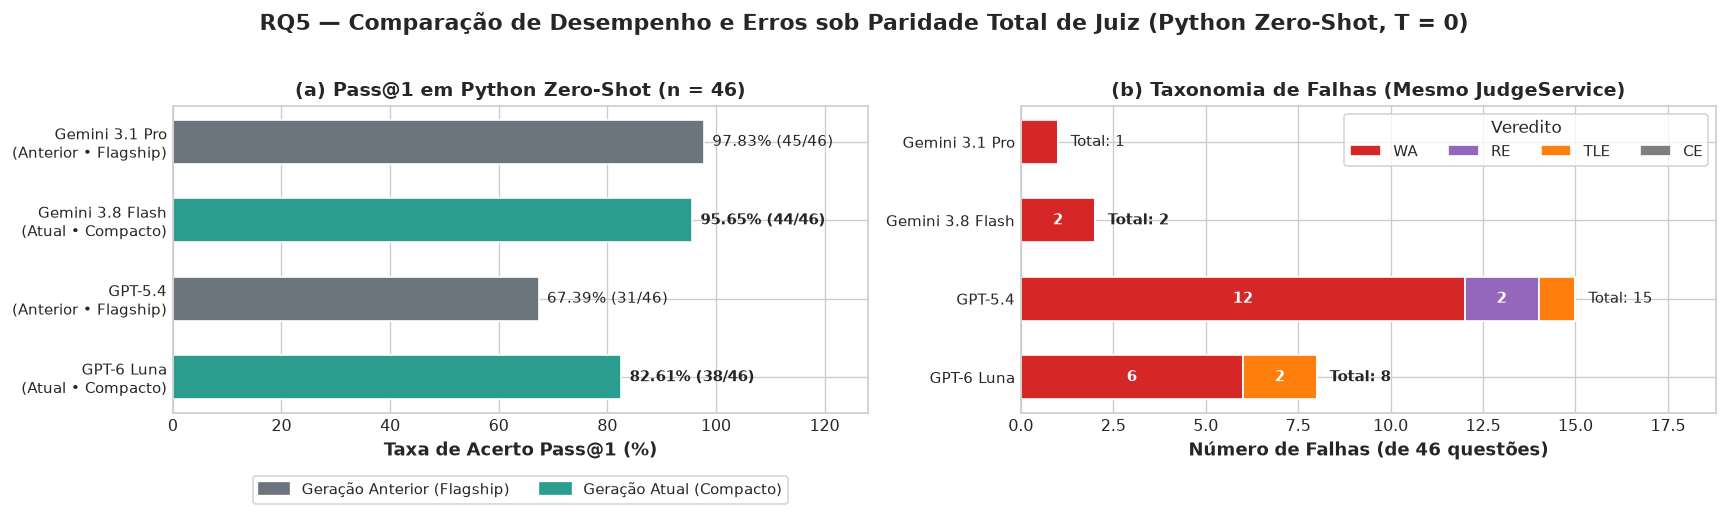

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14.5, 4.3))

order_plot = ["Gemini 3.1 Pro", "Gemini 3.8 Flash", "GPT-5.4", "GPT-6 Luna"]
df_p = df_summary.set_index("Modelo").loc[order_plot].reset_index()

# (a) Pass@1 horizontal
y = np.arange(len(df_p))[::-1]
colors_a = [PALETTE_GEN[g] for g in df_p["Geração"]]
bars_a = axes[0].barh(y, df_p["Pass@1 (%)"], color=colors_a, edgecolor="white", height=0.56)
axes[0].set_yticks(y)
axes[0].set_yticklabels([f"{r['Modelo']}\n({r['Geração']} • {r['Porte']})" for _, r in df_p.iterrows()], fontsize=9.2)
axes[0].set_xlabel("Taxa de Acerto Pass@1 (%)")
axes[0].set_xlim(0, 128)
axes[0].set_title("(a) Pass@1 em Python Zero-Shot (n = 46)")
for b, (_, r) in zip(bars_a, df_p.iterrows()):
    axes[0].text(b.get_width() + 1.5, b.get_y() + b.get_height()/2,
                 f"{r['Pass@1 (%)']:.2f}% ({int(r['AC'])}/46)",
                 va="center", fontweight="bold" if r["Geração"]=="Atual" else "normal", fontsize=9.2)
axes[0].legend(handles=[
    mpatches.Patch(color=PALETTE_GEN["Anterior"], label="Geração Anterior (Flagship)"),
    mpatches.Patch(color=PALETTE_GEN["Atual"], label="Geração Atual (Compacto)"),
], loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=2, frameon=True, facecolor="white")

# (b) Decomposição de erros (não-AC)
err_cols = ["WA", "RE", "TLE", "CE"]
left = np.zeros(len(df_p))
for c in err_cols:
    vals = df_p[c].values.astype(float)
    axes[1].barh(y, vals, left=left, label=c, color=PALETTE_VERDICTS[c], edgecolor="white", height=0.56)
    for i, v in enumerate(vals):
        if v >= 2:
            axes[1].text(left[i] + v/2, y[i], str(int(v)), ha="center", va="center", color="white", fontweight="bold", fontsize=9)
    left += vals
for i, tot in enumerate(left):
    axes[1].text(tot + 0.35, y[i], f"Total: {int(tot)}", va="center", fontsize=9.2, fontweight="bold" if df_p.iloc[i]["Geração"]=="Atual" else "normal")

axes[1].set_yticks(y)
axes[1].set_yticklabels([r["Modelo"] for _, r in df_p.iterrows()], fontsize=9.2)
axes[1].set_xlabel("Número de Falhas (de 46 questões)")
axes[1].set_xlim(0, left.max() + 3.8)
axes[1].set_title("(b) Taxonomia de Falhas (Mesmo JudgeService)")
axes[1].legend(title="Veredito", loc="upper right", ncol=4, frameon=True, facecolor="white")

plt.suptitle("RQ5 — Comparação de Desempenho e Erros sob Paridade Total de Juiz (Python Zero-Shot, T = 0)", fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

## 2. Transições Intrafamília e Desempenho por Etapa da OBI

=== BALANÇO DE TRANSIÇÕES INTRAFAMÍLIA (ANTERIOR → ATUAL, n = 46) ===
  Gemini (3.1 Pro → 3.8 Flash)  : + 0 ganhos | -1 regressões | estável AC=44, não-AC=1
     Regressões: ['Arco e flecha (AC→WA)']
  GPT    (5.4 → 6 Luna)         : + 8 ganhos | -1 regressões | estável AC=30, não-AC=7
     Ganhos:     ['Arco e flecha (RE→AC)', 'Brigadeiros (WA→AC)', 'Calçada Imperial (WA→AC)', 'Cortando o Papel (WA→AC)', 'Metrô da Nlogônia (WA→AC)', 'Nova avenida (WA→AC)', 'Retas (WA→AC)', 'Retângulo (WA→AC)']
     Regressões: ['Jogo da Vida (AC→WA)']

=== QUESTÕES COM ALGUMA FALHA ENTRE OS 4 MODELOS (16 de 46; nas demais 30 houve AC unânime) ===


,Ano,Questão,Etapa,Gemini 3.1 Pro,Gemini 3.8 Flash,GPT-5.4,GPT-6 Luna
0,2016,Arco e flecha,Fase 2 / Estadual,AC,WA,RE,AC
1,2024,Brigadeiros,Fase 3 / Nacional,AC,AC,WA,AC
2,2024,Burocracia,Fase 3 / Nacional,AC,AC,RE,WA
3,2019,Calçada Imperial,Fase 1 / Local,AC,AC,WA,AC
4,2019,Chuva_2019,Fase 1 / Local,AC,AC,TLE,WA
5,2022,Construção de Rodovia,Fase 3 / Nacional,WA,WA,WA,WA
6,2017,Cortando o Papel,Fase 2 / Estadual,AC,AC,WA,AC
7,2017,Dario e Xerxes,Fase 2 / Estadual,AC,AC,WA,WA
8,2021,Dona Minhoca,Fase 3 / Nacional,AC,AC,WA,WA
9,2023,Fast-Food,Fase 3 / Nacional,AC,AC,WA,TLE


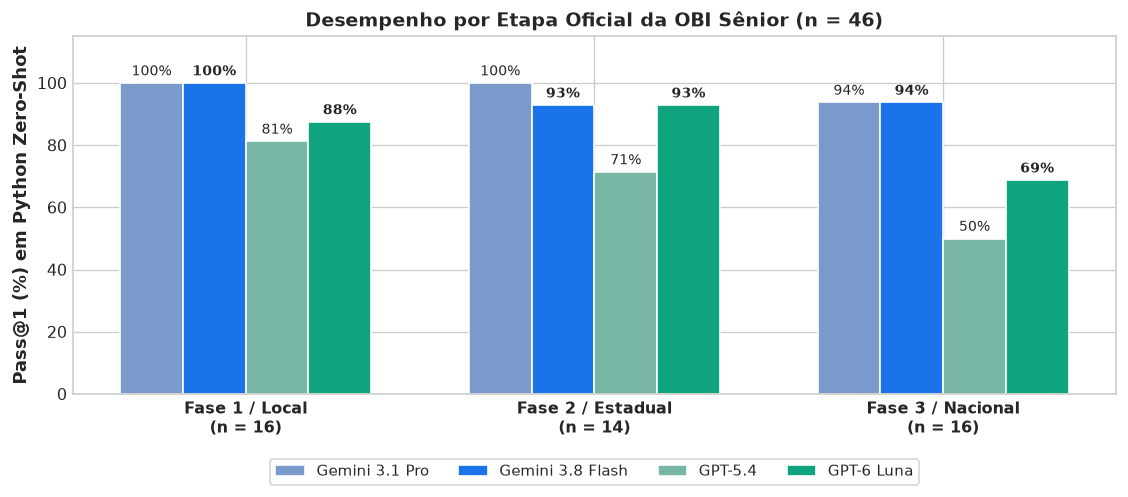

In [7]:
# 2.1 Balanço de transições intrafamília
print("=== BALANÇO DE TRANSIÇÕES INTRAFAMÍLIA (ANTERIOR → ATUAL, n = 46) ===")
for fam, col_old, col_new in [
    ("Gemini (3.1 Pro → 3.8 Flash)", "veredito_gemini_3_1_pro", "veredito_gemini_3_8_flash"),
    ("GPT    (5.4 → 6 Luna)",        "veredito_gpt_5_4",        "veredito_gpt_6_luna"),
]:
    gains = df[(df[col_old] != "AC") & (df[col_new] == "AC")]
    regs  = df[(df[col_old] == "AC") & (df[col_new] != "AC")]
    both_ac = int(((df[col_old] == "AC") & (df[col_new] == "AC")).sum())
    both_no = int(((df[col_old] != "AC") & (df[col_new] != "AC")).sum())
    print(f"  {fam:30s}: +{len(gains):2d} ganhos | -{len(regs)} regressões | estável AC={both_ac}, não-AC={both_no}")
    if len(gains):
        print(f"     Ganhos:     {[f'{r.question_name} ({r[col_old]}→AC)' for _, r in gains.iterrows()]}")
    if len(regs):
        print(f"     Regressões: {[f'{r.question_name} (AC→{r[col_new]})' for _, r in regs.iterrows()]}")

# 2.2 Tabela enxuta das questões onde ao menos 1 dos 4 modelos não obteve AC
vcols_4 = [
    "veredito_gemini_3_1_pro", "veredito_gemini_3_8_flash",
    "veredito_gpt_5_4", "veredito_gpt_6_luna"
]
df_div = df[df[vcols_4].ne("AC").any(axis=1)][["year", "question_name", "fase"] + vcols_4].copy()
df_div.columns = ["Ano", "Questão", "Etapa", "Gemini 3.1 Pro", "Gemini 3.8 Flash", "GPT-5.4", "GPT-6 Luna"]
print(f"\n=== QUESTÕES COM ALGUMA FALHA ENTRE OS 4 MODELOS ({len(df_div)} de 46; nas demais {N - len(df_div)} houve AC unânime) ===")
display(df_div.reset_index(drop=True))

# 2.3 Estratificação por etapa oficial da OBI + Figura 2
fase_order = ["Fase 1 / Local", "Fase 2 / Estadual", "Fase 3 / Nacional"]
mat = np.zeros((len(order_plot), len(fase_order)))
fase_ns = [int((df["fase"] == f).sum()) for f in fase_order]

slug_by_name = {name: slug for name, _, _, _, slug in MODELS}
for i, m in enumerate(order_plot):
    vcol = f"veredito_{slug_by_name[m]}"
    for j, f in enumerate(fase_order):
        sub = df[df["fase"] == f]
        mat[i, j] = (sub[vcol] == "AC").mean() * 100

fig, ax = plt.subplots(figsize=(9.5, 4.3))
x = np.arange(len(fase_order))
w = 0.18
bar_colors = ["#7b9acc", "#1a73e8", "#77b5a5", "#10a37f"]

for i, m in enumerate(order_plot):
    offset = (i - 1.5) * w
    bars = ax.bar(x + offset, mat[i], width=w, label=m, color=bar_colors[i], edgecolor="white")
    for b, val in zip(bars, mat[i]):
        ax.text(b.get_x() + b.get_width()/2, val + 1.4, f"{val:.0f}%", ha="center", va="bottom", fontsize=8.3,
                fontweight="bold" if i in (1, 3) else "normal")

ax.set_xticks(x)
ax.set_xticklabels([f"{f}\n(n = {n})" for f, n in zip(fase_order, fase_ns)], fontweight="bold")
ax.set_ylabel("Pass@1 (%) em Python Zero-Shot")
ax.set_ylim(0, 115)
ax.set_title("Desempenho por Etapa Oficial da OBI Sênior (n = 46)")
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.16), ncol=4, frameon=True, facecolor="white", fontsize=8.8)
plt.tight_layout()
plt.show()

## 3. Eficiência Econômica e Fronteira de Pareto

=== SENSIBILIDADE ECONÔMICA — FAMÍLIA GEMINI (n = 46, Python Zero-Shot) ===
  Gemini 3.1 Pro (Flagship):        $2.8602 total | $0.06356/AC (45 AC)
  Gemini 3.8 Flash (registrado):    $0.0994 total | $0.00226/AC (44 AC) → 28.1× mais barato/AC
  Gemini 3.8 Flash (c/ thinking*):  $0.3828 total | $0.00870/AC (44 AC) → 7.3× mais barato/AC
  (*thinking tokens nas 46 questões: 75,571 tokens | média de 1642.8/questão)


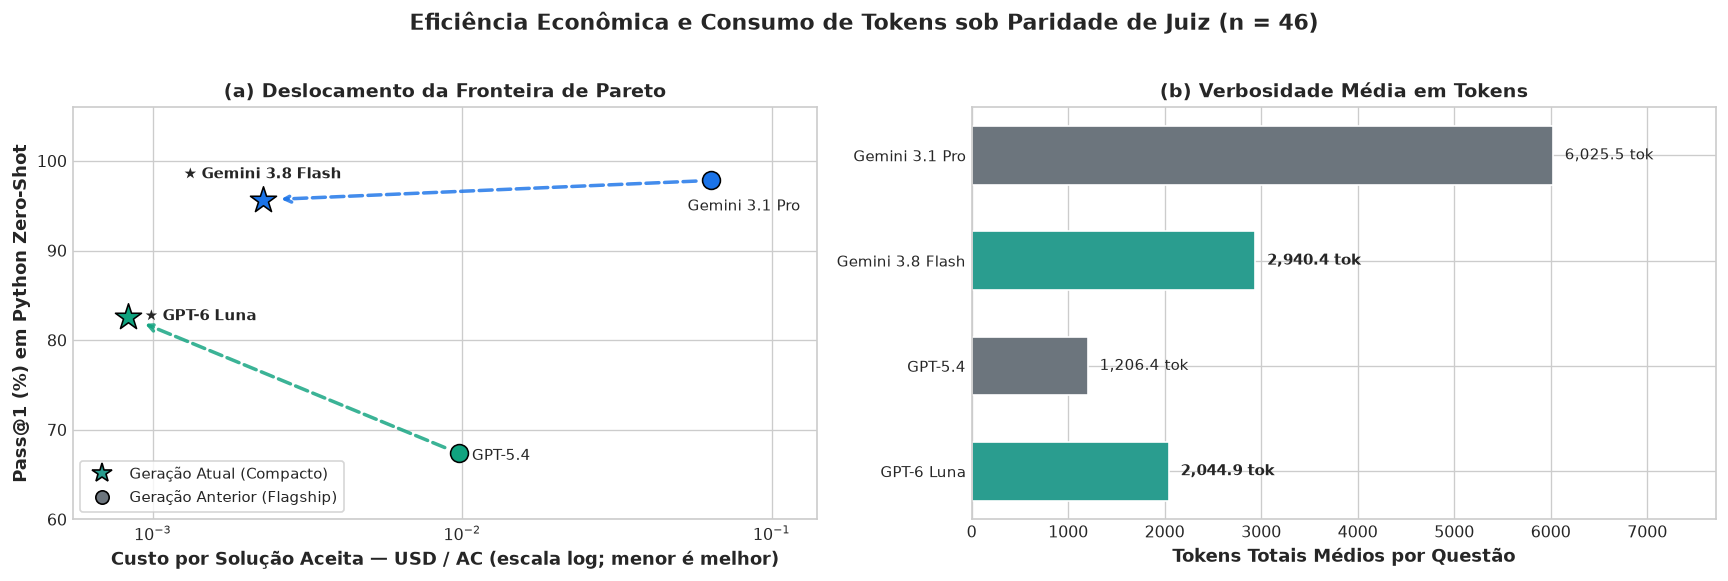

In [8]:
# Análise de sensibilidade dos thinking tokens do Gemini 3.8 Flash (lendo dos JSONs do próprio TCC)
in_g38, out_g38, tot_g38 = 0, 0, 0
for q in df["question_name"]:
    jf = TCC_RES_PATH / "gemini-3.8-flash" / "zero_shot" / "python" / "text" / f"{q}.json"
    e = json.loads(jf.read_text(encoding="utf-8"))[0]
    in_g38 += int(e["tokens"]["input_tokens"])
    out_g38 += int(e["tokens"]["output_tokens"])
    tot_g38 += int(e["tokens"]["total_tokens"])

think_g38 = max(0, tot_g38 - in_g38 - out_g38)
cost_g38_rec = float(df["custo_gemini_3_8_flash"].sum())
cost_g38_think = (in_g38 / 1e6) * 0.75 + ((out_g38 + think_g38) / 1e6) * 3.75
ac_g38 = int((df["veredito_gemini_3_8_flash"] == "AC").sum())
c_ac_g31 = float(df_summary[df_summary["Modelo"] == "Gemini 3.1 Pro"]["Custo / AC (USD)"].iloc[0])

print("=== SENSIBILIDADE ECONÔMICA — FAMÍLIA GEMINI (n = 46, Python Zero-Shot) ===")
print(f"  Gemini 3.1 Pro (Flagship):        ${df['custo_gemini_3_1_pro'].sum():.4f} total | ${c_ac_g31:.5f}/AC (45 AC)")
print(f"  Gemini 3.8 Flash (registrado):    ${cost_g38_rec:.4f} total | ${cost_g38_rec/ac_g38:.5f}/AC ({ac_g38} AC) → {c_ac_g31/(cost_g38_rec/ac_g38):.1f}× mais barato/AC")
print(f"  Gemini 3.8 Flash (c/ thinking*):  ${cost_g38_think:.4f} total | ${cost_g38_think/ac_g38:.5f}/AC ({ac_g38} AC) → {c_ac_g31/(cost_g38_think/ac_g38):.1f}× mais barato/AC")
print(f"  (*thinking tokens nas 46 questões: {think_g38:,} tokens | média de {think_g38/N:.1f}/questão)")

# Figura 3: Painel Duplo — (a) Fronteira de Pareto; (b) Tokens Médios
fig, axes = plt.subplots(1, 2, figsize=(14.5, 4.7))

pts = {}
for _, r in df_p.iterrows():
    m = r["Modelo"]
    xv, yv = r["Custo / AC (USD)"], r["Pass@1 (%)"]
    pts[m] = (xv, yv)
    mk = "*" if r["Geração"] == "Atual" else "o"
    sz = 270 if mk == "*" else 115
    axes[0].scatter(xv, yv, marker=mk, s=sz, color=PALETTE_FAMILY[r["Família"]],
                    edgecolors="black", linewidth=0.95, zorder=5)

offsets = {
    "Gemini 3.1 Pro":   (-14, -18),
    "Gemini 3.8 Flash": (0, 13),
    "GPT-5.4":          (8, -4),
    "GPT-6 Luna":       (10, -2),
}
for m, (xv, yv) in pts.items():
    dx, dy = offsets[m]
    is_new = df_p[df_p["Modelo"] == m]["Geração"].iloc[0] == "Atual"
    axes[0].annotate(f"{'★ ' if is_new else ''}{m}", (xv, yv), xytext=(dx, dy),
                     textcoords="offset points",
                     ha="center" if m == "Gemini 3.8 Flash" else "left",
                     fontsize=9.2, fontweight="bold" if is_new else "normal")

for src, dst, col in [
    ("Gemini 3.1 Pro", "Gemini 3.8 Flash", PALETTE_FAMILY["Gemini"]),
    ("GPT-5.4", "GPT-6 Luna", PALETTE_FAMILY["GPT"]),
]:
    axes[0].annotate("", xy=pts[dst], xytext=pts[src],
                     arrowprops=dict(arrowstyle="->", color=col, lw=2.1, ls="--", alpha=0.82, shrinkA=9, shrinkB=11))

axes[0].set_xscale("log")
axes[0].set_xlabel("Custo por Solução Aceita — USD / AC (escala log; menor é melhor)")
axes[0].set_ylabel("Pass@1 (%) em Python Zero-Shot")
axes[0].set_xlim(0.00055, 0.14)
axes[0].set_ylim(60, 106)
axes[0].set_title("(a) Deslocamento da Fronteira de Pareto")
axes[0].legend(handles=[
    plt.Line2D([0], [0], marker="*", color="w", label="Geração Atual (Compacto)", markerfacecolor="#2a9d8f", markeredgecolor="black", markersize=12),
    plt.Line2D([0], [0], marker="o", color="w", label="Geração Anterior (Flagship)", markerfacecolor="#6c757d", markeredgecolor="black", markersize=8),
], loc="lower left", frameon=True, facecolor="white")

# (b) Tokens Médios por Questão
y = np.arange(len(df_p))[::-1]
bars_t = axes[1].barh(y, df_p["Tokens Médios"], color=[PALETTE_GEN[g] for g in df_p["Geração"]], edgecolor="white", height=0.56)
axes[1].set_yticks(y)
axes[1].set_yticklabels(df_p["Modelo"], fontsize=9.2)
axes[1].set_xlabel("Tokens Totais Médios por Questão")
axes[1].set_xlim(0, df_p["Tokens Médios"].max() * 1.28)
axes[1].set_title("(b) Verbosidade Média em Tokens")
for b, (_, r) in zip(bars_t, df_p.iterrows()):
    axes[1].text(b.get_width() + 120, b.get_y() + b.get_height()/2,
                 f"{r['Tokens Médios']:,.1f} tok", va="center",
                 fontweight="bold" if r["Geração"]=="Atual" else "normal", fontsize=9.0)

plt.suptitle("Eficiência Econômica e Consumo de Tokens sob Paridade de Juiz (n = 46)", fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()